DAY-1 (CLEANING, TARGET_IMBALANCE)

In [1]:
import pandas as pd
import numpy as np

# 1. Load the dataset into a pandas DataFrame
df = pd.read_csv('survey_lung_cancer.csv')

In [2]:
# 2. View shape and initial rows
print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (309, 16)

First 5 rows:


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,MALE,69,0,1,1,0,0,1,0,1,1,1,1,1,1,YES
1,MALE,74,1,0,0,0,1,1,1,0,0,0,1,1,1,YES
2,FEMALE,59,0,0,0,1,0,1,0,1,0,1,1,0,1,NO
3,MALE,63,1,1,1,0,0,0,0,0,1,0,0,1,1,NO
4,FEMALE,63,0,1,0,0,0,0,0,1,0,1,1,0,0,NO


In [3]:
# 3. Check column types and missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64


In [4]:
# 4. Check for duplicates and remove them
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicate_count}")
df = df.drop_duplicates()
print(f"Shape after removing duplicates: {df.shape}")


Duplicate rows found: 33
Shape after removing duplicates: (276, 16)


In [5]:
df['GENDER'] = df['GENDER'].astype(str).str.strip().str.upper().map({'M': 1, 'MALE': 1,'F': 0, 'FEMALE': 0})
if 'LUNG_CANCER' in df.columns:
    df['LUNG_CANCER'] = df['LUNG_CANCER'].astype(str).str.strip().str.upper().map({'YES': 1, 'Y': 1,'NO': 0, 'N': 0})
    
    symptom_cols = [c for c in df.columns if c not in ['GENDER', 'AGE', 'LUNG_CANCER']]

# If values are -1 and 0, convert to 0 and 1:
for col in symptom_cols:
    if (df[col] == -1).any():
        df[col] = df[col].replace({-1: 0, 0: 1})
    elif set(df[col].dropna().unique()).issubset({1, 2}):
        df[col] = df[col].replace({1: 0, 2: 1})

In [6]:
display(df.head(3))

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1
1,1,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1
2,0,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0


In [30]:
df[['SMOKING', 'YELLOW_FINGERS', 'ANXIETY']].value_counts()

SMOKING  YELLOW_FINGERS  ANXIETY
1        1               1          76
         0               0          56
0        1               1          41
         0               0          41
         1               0          33
         0               1          11
1        0               1           9
         1               0           9
Name: count, dtype: int64

In [8]:
# 7. Verify the clean table
print(f"Shape: {df.shape}")
print("\nCheck Missing Values (should all be 0):")
print(df.isnull().sum())

Shape: (276, 16)

Check Missing Values (should all be 0):
GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64


In [9]:
# 8. Check Target Distribution (Class Imbalance)
print("\nTarget Class Distribution:")
print(df['LUNG_CANCER'].value_counts(normalize=True))
display(df.head())


Target Class Distribution:
LUNG_CANCER
1    0.862319
0    0.137681
Name: proportion, dtype: float64


,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1
1,1,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1
2,0,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0
3,1,63,1,1,1,0,0,0,0,0,1,0,0,1,1,0
4,0,63,0,1,0,0,0,0,0,1,0,1,1,0,0,0


DAY-2 ( Train_Test_Split, LR, RF, Confusion_Matrix, ROC-AUC)

In [10]:
from sklearn.model_selection import train_test_split

# Separate features (X) and label (y)
X = df.drop(columns=['LUNG_CANCER'])
y = df['LUNG_CANCER']

# Split 80% training, 20% test
# stratify=y preserves the 86:14 ratio in both train and test splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"Train label balance:\n{y_train.value_counts(normalize=True)}")

X_train shape: (220, 15)
X_test shape:  (56, 15)
Train label balance:
LUNG_CANCER
1    0.863636
0    0.136364
Name: proportion, dtype: float64


In [12]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score

In [13]:
# 1. Train Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [14]:
# 2. Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [15]:
# 3. Helper function to compute clinical metrics
def evaluate_model(name, model, X_test, y_test):
  # 1. Get binary predictions (0 or 1) and risk probabilities (0.0 to 1.0)
  preds = model.predict(X_test)
  probs = model.predict_proba(X_test)[:, 1]

  # 2. Extract outcome counts from confusion matrix
  # tn = True Negatives, fp = False Positives, fn = False Negatives, tp = True Positives
  tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

  # 3. Calculate clinical metrics
  sensitivity = tp / (tp + fn)  # Cancers detected out of total actual cancers
  specificity = tn / (tn + fp)  # Healthy cases cleared out of total healthy
  auc = roc_auc_score(y_test, probs)  # Overall ability to separate risk

  return {
      "Model": name,
      "Sensitivity": round(sensitivity, 3),
      "Specificity": round(specificity, 3),
      "AUC-ROC": round(auc, 3),
  }

In [16]:
# 4. Generate the Results Table
results = [evaluate_model("Logistic Regression", lr, X_test, y_test),
           evaluate_model("Random Forest", rf, X_test, y_test)]

results_df = pd.DataFrame(results)
display(results_df)

,Model,Sensitivity,Specificity,AUC-ROC
0,Logistic Regression,0.979,0.50,0.945
1,Random Forest,0.958,0.75,0.956


DAY-4 (XGBoost,Cross-Validation,Calibration)

In [17]:
import xgboost as xgb

# 1. Re-train Logistic Regression with class weighting
lr_balanced = LogisticRegression(
    max_iter=1000, class_weight='balanced', random_state=42
)
lr_balanced.fit(X_train, y_train)

# 2. Re-train Random Forest with class weighting
rf_balanced = RandomForestClassifier(
    n_estimators=100, class_weight='balanced', random_state=42
)
rf_balanced.fit(X_train, y_train)

# 3. Train XGBoost
# Compute ratio of negative to positive cases for scale_pos_weight
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    scale_pos_weight=neg_pos_ratio,
    eval_metric='logloss',
    random_state=42,
)
xgb_model.fit(X_train, y_train)

# 4. Compare all updated models in a new table
updated_results = [
    evaluate_model('LR (Balanced)', lr_balanced, X_test, y_test),
    evaluate_model('RF (Balanced)', rf_balanced, X_test, y_test),
    evaluate_model('XGBoost', xgb_model, X_test, y_test),
]

display(pd.DataFrame(updated_results))

,Model,Sensitivity,Specificity,AUC-ROC
0,LR (Balanced),0.854,1.000,0.958
1,RF (Balanced),0.938,0.875,0.964
2,XGBoost,0.917,1.000,0.953


In [18]:
import joblib

# Save the trained Random Forest model to disk (winning model based on its AUC-ROC score)
joblib.dump(rf_balanced, 'cancer_risk_model.pkl')
print("Model saved successfully as cancer_risk_model.pkl")

Model saved successfully as cancer_risk_model.pkl


5-Fold Cross-Validation AUC-ROC Scores:
[0.96  0.878 0.909 0.943 0.967]
Average AUC across 5 splits: 0.931


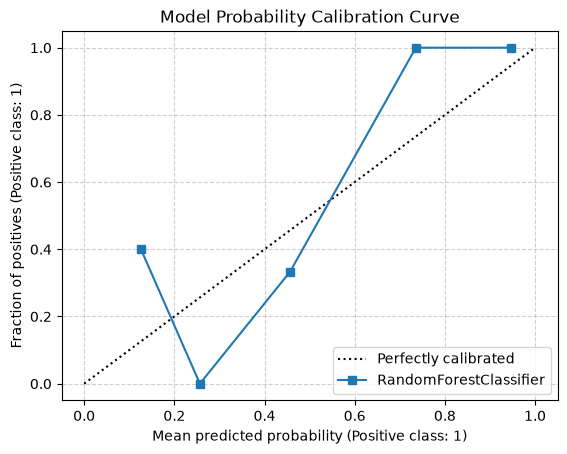

In [19]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import cross_val_score

# 1. Cross-validation: score the model on 5 different splits
cv_scores = cross_val_score(rf_balanced, X, y, cv=5, scoring="roc_auc")
print("5-Fold Cross-Validation AUC-ROC Scores:")
print(cv_scores.round(3))
print("Average AUC across 5 splits:", cv_scores.mean().round(3))

# 2. Calibration plot: check probability reliability
CalibrationDisplay.from_estimator(rf_balanced, X_test, y_test, n_bins=5)

plt.title("Model Probability Calibration Curve")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

DAY-5 (Shap Feature Importance and Explanations)

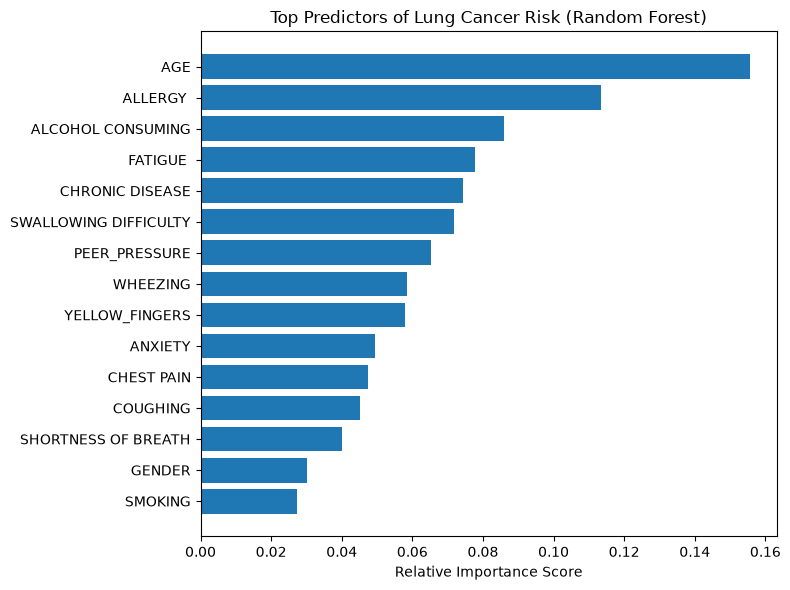


Top 5 Most Influential Features:
          Feature  Importance
              AGE    0.155548
         ALLERGY     0.113452
ALCOHOL CONSUMING    0.085993
         FATIGUE     0.077700
  CHRONIC DISEASE    0.074445


In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract feature importances from the trained Random Forest
importances = rf_balanced.feature_importances_
feature_names = X.columns

# 2. Put them in a DataFrame and sort from highest to lowest
imp_feat_df = pd.DataFrame({'Feature': feature_names,'Importance': importances}).sort_values(by='Importance', ascending=True)

# 3. Plot a horizontal bar chart
plt.figure(figsize=(8, 6))
plt.barh(imp_feat_df['Feature'], imp_feat_df['Importance'], color='#1f77b4')
plt.xlabel('Relative Importance Score')
plt.title('Top Predictors of Lung Cancer Risk (Random Forest)')
plt.tight_layout()
plt.show()

# 4. Display the top 5 most important features
print("\nTop 5 Most Influential Features:")
print(imp_feat_df.tail(5).iloc[::-1].to_string(index=False))

C:\Users\HP\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


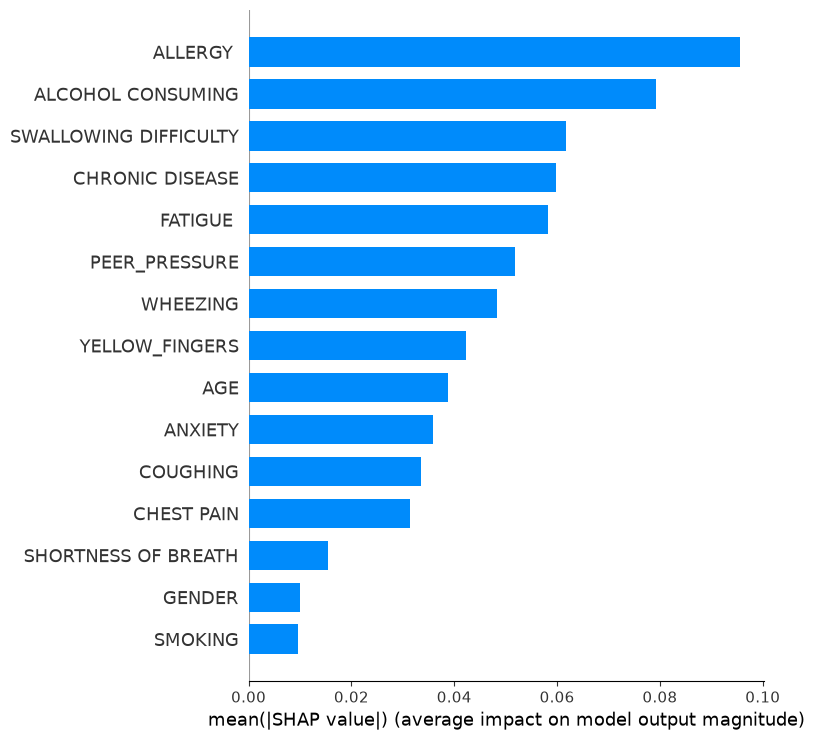

Top 3 Risk Factors for Patient #0:
ALLERGY              0.121293
ALCOHOL CONSUMING    0.082437
CHRONIC DISEASE      0.062467
dtype: float64


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 1. Compute SHAP values for the Random Forest model
explainer = shap.TreeExplainer(rf_balanced)
shap_values = explainer.shap_values(X_test)

# Select the cancer (positive class) impact matrix
cancer_shap = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values[1]

# 2. Plot overall symptom impact
shap.summary_plot(cancer_shap, X_test, plot_type="bar")

# 3. Print Top 3 risk factors for Patient #0
patient_factors = pd.Series(cancer_shap[0], index=X_test.columns).sort_values(ascending=False)
print("Top 3 Risk Factors for Patient #0:")
print(patient_factors.head(3))

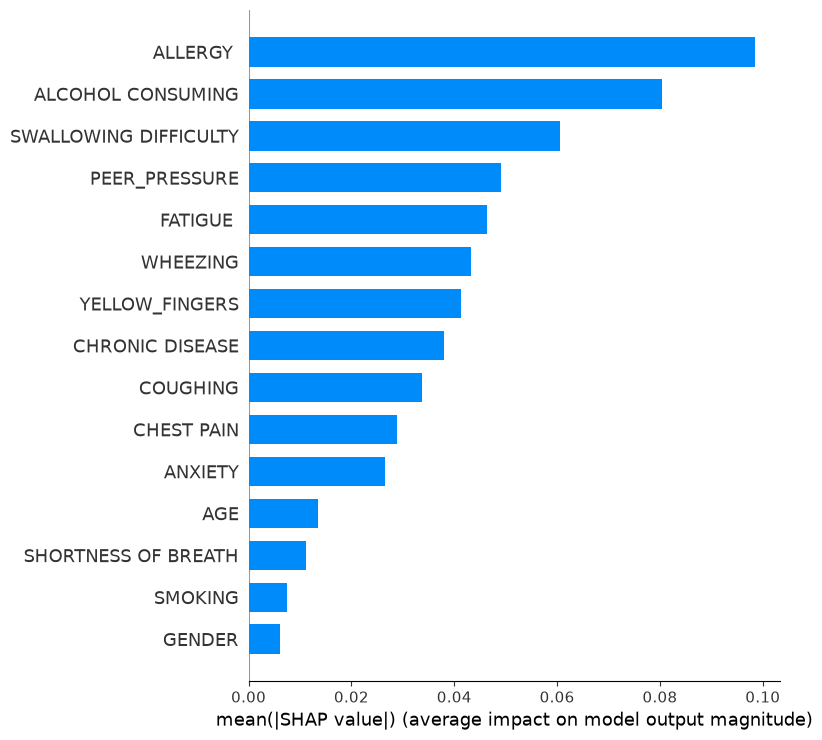

ALLERGY              0.123986
ALCOHOL CONSUMING    0.109460
WHEEZING             0.056331
dtype: float64


In [22]:
import shap
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 1. Retrain with a depth limit so symptoms get used
rf_balanced = RandomForestClassifier(
    n_estimators=100, 
    max_depth=4, 
    max_features="sqrt", 
    class_weight="balanced", 
    random_state=42
)
rf_balanced.fit(X_train, y_train)

# 2. Recompute SHAP values
explainer = shap.TreeExplainer(rf_balanced)
shap_values = explainer.shap_values(X_test)
cancer_shap = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values[1]

# 3. Plot symptom impact
shap.summary_plot(cancer_shap, X_test, plot_type="bar")

# 4. Check Top 3 for Patient #0
print(pd.Series(cancer_shap[0], index=X_test.columns).sort_values(ascending=False).head(3))

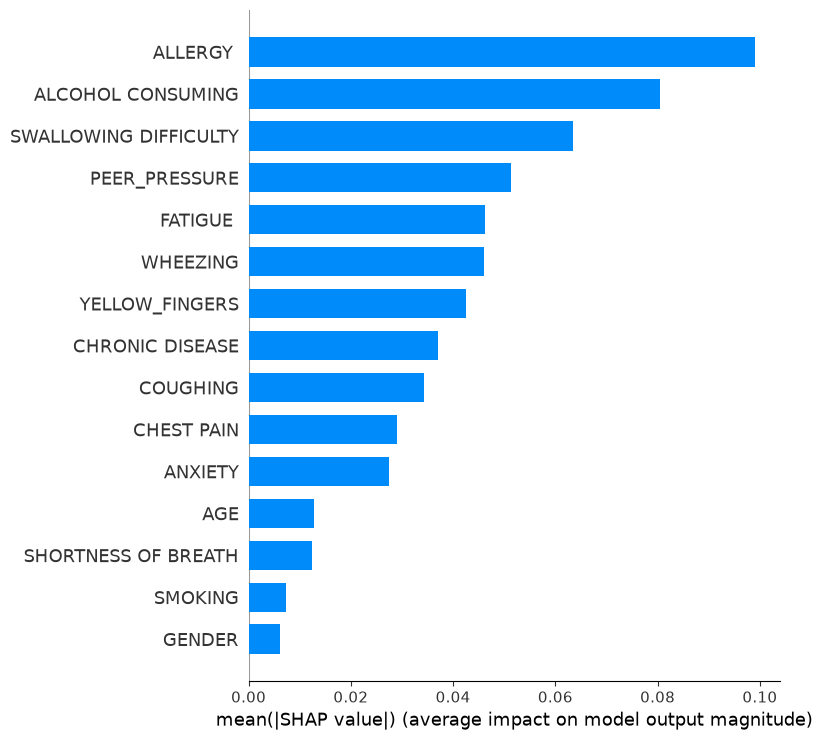


Top 3 Factors for Patient #0:
ALLERGY              0.121274
ALCOHOL CONSUMING    0.111793
WHEEZING             0.064574
dtype: float64


In [23]:
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier

# 1. Bin AGE into 4 categorical risk buckets (0, 1, 2, 3)
X_train_binned = X_train.copy()
X_test_binned = X_test.copy()

X_train_binned['AGE'] = pd.qcut(X_train['AGE'], q=4, labels=False)
X_test_binned['AGE'] = pd.qcut(X_test['AGE'], q=4, labels=False)

# 2. Retrain Random Forest
rf_binned = RandomForestClassifier(
    n_estimators=100, 
    max_depth=4, 
    class_weight='balanced', 
    random_state=42
)
rf_binned.fit(X_train_binned, y_train)

# 3. Compute SHAP on the binned model
explainer = shap.TreeExplainer(rf_binned)
shap_vals = explainer.shap_values(X_test_binned)
cancer_shap = shap_vals[:, :, 1] if shap_vals.ndim == 3 else shap_vals[1]

# 4. Plot global feature importance
shap.summary_plot(cancer_shap, X_test_binned, plot_type="bar")

# 5. Check Top 3 symptoms for Patient #0
print("\nTop 3 Factors for Patient #0:")
print(pd.Series(cancer_shap[0], index=X_test.columns).sort_values(ascending=False).head(3))

In [24]:
X_train.describe().T[['min','mean','max']]

,min,mean,max
GENDER,0.0,0.527273,1.0
AGE,38.0,63.386364,87.0
SMOKING,0.0,0.559091,1.0
YELLOW_FINGERS,0.0,0.600000,1.0
ANXIETY,0.0,0.490909,1.0
PEER_PRESSURE,0.0,0.481818,1.0
CHRONIC DISEASE,0.0,0.527273,1.0
FATIGUE,0.0,0.659091,1.0
ALLERGY,0.0,0.536364,1.0
WHEEZING,0.0,0.531818,1.0


In [25]:
df.head(3)

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,1,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1
1,1,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1
2,0,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0


In [31]:
# 1. Check Data Variance (Confirm no more all-zero columns)
symptom_means = X_train.drop(columns=['AGE', 'GENDER']).mean()
all_columns_have_signal = (symptom_means > 0).all() and (symptom_means < 1).all()

# 2. Check Predictions (Confirm model isn't predicting only one class)
predictions = rf_balanced.predict(X_test)
has_both_classes = len(set(predictions)) > 1

# 3. Check Feature Importances (Confirm symptoms have non-zero importance)
symptom_importances = pd.Series(rf_balanced.feature_importances_, index=X.columns).drop(['AGE', 'GENDER'])
symptoms_used = (symptom_importances > 0).all()

# 4. Check SHAP Values (Confirm symptoms have real non-zero SHAP impact)
shap_impact_present = (cancer_shap.sum(axis=0) != 0).all()

print("--- Pipeline Health Checklist ---")
print(f"1. Symptoms contain real variation (0s and 1s): {'PASS' if all_columns_have_signal else 'FAIL'}")
print(f"2. Model predicts both classes (Healthy & Cancer): {'PASS' if has_both_classes else 'FAIL'}")
print(f"3. Symptoms actively used in Random Forest:       {'PASS' if symptoms_used else 'FAIL'}")
print(f"4. Symptoms show non-zero impact in SHAP:        {'PASS' if shap_impact_present else 'FAIL'}")

--- Pipeline Health Checklist ---
1. Symptoms contain real variation (0s and 1s): PASS
2. Model predicts both classes (Healthy & Cancer): PASS
3. Symptoms actively used in Random Forest:       PASS
4. Symptoms show non-zero impact in SHAP:        PASS
